# 04 · Retention Strategy: from predictions to an action list

**Project:** E-Commerce Customer Segmentation & Retention (Python + SQL + ML)

### Why this notebook exists
A churn score on its own does not make money. A business needs to know **who to contact first, with what message, and how much is at stake**.
Here I combine the three things I built:
1. **Segments** (SQL RFM + K-Means) → *who the customer is*
2. **Churn risk** (ML model) → *how likely they are to leave*
3. **Customer value** → *how much it hurts if they do*

Then I create a **prioritised retention list** and a simple value estimate for a campaign.

## Step 0 · Setup

In [1]:
import sys
sys.path.append("../src")
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from db_utils import read_sql_or_csv

sns.set_theme(style="whitegrid", palette="deep")
pd.options.display.float_format = "{:,.2f}".format
pd.options.display.width = 200
PROCESSED, IMAGES, OUTPUTS = Path("../data/processed"), Path("../images"), Path("../outputs")

## Step 1 · Bring everything together
**What:** load segments (notebook 02), churn scores (notebook 03) and the RFM table (for tenure). **Why:** one table per customer with every piece of information.

In [2]:
segments = pd.read_csv(PROCESSED / "customer_segments.csv")            # customer_id, SQL segment, K-Means cluster
scores = pd.read_csv(PROCESSED / "churn_scores.csv")                   # customer_id, churn_risk (active customers only)
rfm = read_sql_or_csv("SELECT customer_id, tenure_days FROM customer_rfm", csv_fallback=PROCESSED / "customer_rfm.csv")

# merge step by step. how="inner" keeps only customers that exist in BOTH tables.
base = segments.merge(rfm, on="customer_id", how="left")               # add tenure to the segment table
plan = scores.merge(base, on="customer_id", how="inner")               # active customers that have a score AND a segment

print(f"Segments table : {len(segments):,} customers")
print(f"Scored (active): {len(scores):,} customers")
print(f"Final plan base: {len(plan):,} customers")
print(f"Scored customers dropped in the merge: {len(scores) - len(plan)}  (customers whose net revenue was <= 0 and were excluded from segmentation)")
assert plan["customer_id"].is_unique
plan.head()

Loaded from MySQL
Segments table : 5,832 customers
Scored (active): 3,471 customers
Final plan base: 3,463 customers
Scored customers dropped in the merge: 8  (customers whose net revenue was <= 0 and were excluded from segmentation)


,customer_id,churn_risk,recency_days,frequency,monetary,segment,cluster_id,cluster_name,tenure_days
0,12347,0.21,3,8,"4,921.53",Champions,1,VIP Loyalists,405
1,12348,0.43,76,5,"1,658.40",Loyal Customers,0,Slipping Regulars,439
2,12349,0.58,19,3,"3,654.54",Potential Loyalists,2,Active Newcomers,590
3,12352,0.28,37,9,"1,609.21",Champions,1,VIP Loyalists,393
4,12356,0.34,23,6,"5,611.73",Champions,1,VIP Loyalists,425


**Evaluation:** a handful of scored customers disappear in the merge because they returned more than they bought (excluded in the SQL RFM step). That is consistent with the rules I set earlier, so I accept it.

## Step 2 · Estimate customer value for the next 90 days
**What:** a simple proxy: *average spend per 90 days* = net spend ÷ tenure × 90.
**Why:** the model predicts the **next 90 days**, so I measure value on the same time scale. 
**Design choice:** I set tenure to **at least 90 days** so that a brand-new customer with one big order is not extrapolated to a huge number.
**Limitation:** this is a rough proxy, not a forecast. Seasonality is ignored.

In [3]:
plan["tenure_capped"] = plan["tenure_days"].clip(lower=90)                              # minimum 90 days
plan["value_90d"] = plan["monetary"] / plan["tenure_capped"] * 90                       # typical spend per 90 days (GBP)
plan["revenue_at_risk"] = plan["churn_risk"] * plan["value_90d"]                        # expected loss = probability x value

print(plan[["churn_risk", "value_90d", "revenue_at_risk"]].describe().round(2))

       churn_risk  value_90d  revenue_at_risk
count    3,463.00   3,463.00         3,463.00
mean         0.43     750.71           155.85
std          0.23   2,447.90           148.06
min          0.00       1.10             0.00
25%          0.24     190.37            78.60
50%          0.44     364.90           120.68
75%          0.61     723.22           189.64
max          0.96  70,442.19         3,125.56


**Evaluation:** `value_90d` is very skewed (a few customers are worth thousands of pounds per quarter, most are worth little) — the same pattern found in notebook 01. Because of this, any plan should be **value-weighted**: one high-value customer matters far more than one small customer.

## Step 3 · Priority tiers
### 3a · My first attempt: a risk × value grid (and why it failed)
The classic idea: *high value* (top 20% of `value_90d`) **and** *high risk* (top third of `churn_risk`) = "Save now". I use **relative** cut-offs because notebook 03 showed the probabilities are over-estimated (seasonal shift) while the *ranking* is reliable.

In [4]:
value_cut = plan["value_90d"].quantile(0.80)             # 80th percentile -> top 20% are 'high value'
risk_cut = plan["churn_risk"].quantile(0.667)            # 66.7th percentile -> top third are 'high risk'

first_try = plan[(plan["value_90d"] >= value_cut) & (plan["churn_risk"] >= risk_cut)]    # both conditions at once
print(f"First attempt 'Save now' group: {len(first_try)} customers = {len(first_try)/len(plan):.1%} of active customers, "
      f"{first_try['revenue_at_risk'].sum()/plan['revenue_at_risk'].sum():.1%} of expected revenue at risk")

# WHY so few? check how churn risk and value relate (Spearman = rank correlation, robust to skew)
rho = plan[["churn_risk", "value_90d"]].corr(method="spearman").iloc[0, 1]
print(f"Spearman correlation between churn risk and value: {rho:.2f}")

# average risk by value quintile (1 = lowest value ... 5 = highest value)
print(plan.groupby(pd.qcut(plan["value_90d"], 5, labels=[1, 2, 3, 4, 5]), observed=True)["churn_risk"].mean().round(2))

First attempt 'Save now' group: 13 customers = 0.4% of active customers, 1.9% of expected revenue at risk
Spearman correlation between churn risk and value: -0.79
value_90d
1   0.68
2   0.54
3   0.43
4   0.31
5   0.17
Name: churn_risk, dtype: float64


**Evaluation (the grid idea fails here):** only **13 customers** qualify, and they hold just ~2% of the expected loss — far too small to build a plan on. The reason is the **strong negative correlation (about -0.8)** between value and risk: the customers worth the most are the frequent buyers, and frequency is exactly what the model uses to say "this customer is safe". So *high value and high risk at the same time* is naturally rare. 
This is also a useful finding on its own: **the most valuable customers are mostly healthy right now.**

### 3b · Optimization: rank by expected loss instead
The quantity a retention team really cares about is **expected £ loss = churn risk × value**. It already combines the two ideas, so I rank customers by it and build tiers from the ranking:
- **Tier 1 – Save now:** top 5% by expected loss → personal outreach (affordable: only a few hundred customers)
- **Tier 2 – Targeted offer:** next 15% → email / call with a tailored reorder offer
- **Tier 3 – Protect VIPs:** top-20%-value customers *not* in Tiers 1-2 → healthy and valuable, keep them happy, **don't over-discount**
- **Tier 4 – Automated nurture:** everyone else → standard automated messages

In [5]:
# rank every customer by expected loss (1 = biggest expected loss); method="first" breaks ties by order so ranks are unique
plan["loss_rank_pct"] = plan["revenue_at_risk"].rank(ascending=False, method="first") / len(plan)   # 0..1, small = high loss

def assign_tier(row):
    # decision rules, checked from top to bottom (first match wins)
    if row["loss_rank_pct"] <= 0.05:        return "1 - Save now"              # top 5% expected loss
    if row["loss_rank_pct"] <= 0.20:        return "2 - Targeted offer"        # next 15%
    if row["value_90d"] >= value_cut:       return "3 - Protect VIPs"          # valuable but not at high risk
    return "4 - Automated nurture"

plan["tier"] = plan.apply(assign_tier, axis=1)           # apply the rule row by row

tier_summary = (plan.groupby("tier")
                    .agg(customers=("customer_id", "size"),
                         avg_risk=("churn_risk", "mean"),
                         total_value_90d=("value_90d", "sum"),
                         revenue_at_risk=("revenue_at_risk", "sum")))
tier_summary["pct_customers"] = tier_summary["customers"] / tier_summary["customers"].sum() * 100
tier_summary["pct_revenue_at_risk"] = tier_summary["revenue_at_risk"] / tier_summary["revenue_at_risk"].sum() * 100
tier_summary

,customers,avg_risk,total_value_90d,revenue_at_risk,pct_customers,pct_revenue_at_risk
tier,,,,,,
1 - Save now,173,0.41,"302,211.61","101,656.91",5.00,18.84
2 - Targeted offer,519,0.42,"467,323.14","142,269.56",14.99,26.36
3 - Protect VIPs,386,0.07,"1,129,779.56","33,470.88",11.15,6.20
4 - Automated nurture,2385,0.49,"700,390.45","262,319.33",68.87,48.60


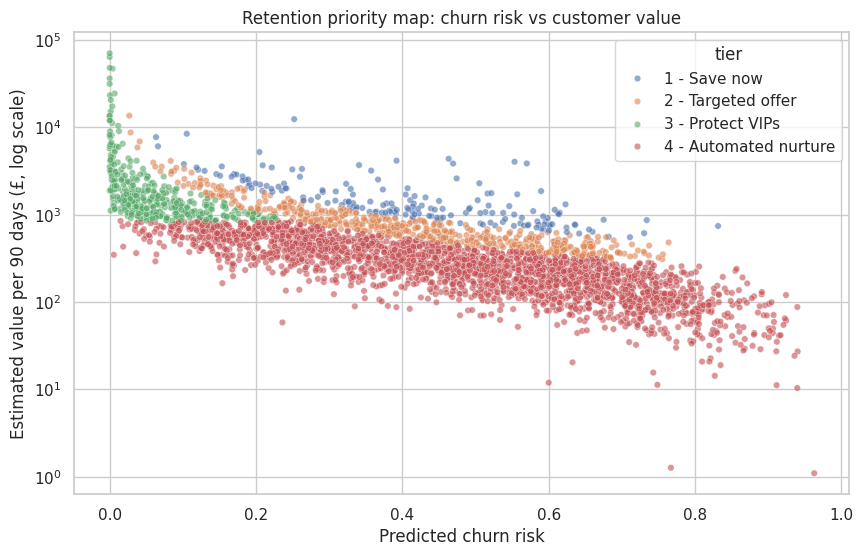

In [6]:
# scatter: each dot is a customer. y-axis is log scale because value is so skewed
fig, ax = plt.subplots(figsize=(10, 6))
sns.scatterplot(data=plan, x="churn_risk", y="value_90d", hue="tier", hue_order=sorted(plan["tier"].unique()),
                alpha=0.6, s=22, ax=ax)
ax.set_yscale("log")
ax.set_title("Retention priority map: churn risk vs customer value")
ax.set_xlabel("Predicted churn risk")
ax.set_ylabel("Estimated value per 90 days (£, log scale)")
plt.savefig(IMAGES / "19_retention_priority_map.png", dpi=150, bbox_inches="tight")
plt.show()

In [7]:
# key findings computed in code so the text always matches the data
t1, t2 = tier_summary.loc["1 - Save now"], tier_summary.loc["2 - Targeted offer"]
total_risk = plan["revenue_at_risk"].sum()
print(f"Total expected revenue at risk (next 90 days, all active customers): £{total_risk:,.0f}")
print(f"Tier 1: {t1['customers']:.0f} customers ({t1['pct_customers']:.0f}% of active) hold {t1['pct_revenue_at_risk']:.0f}% of the expected loss (£{t1['revenue_at_risk']:,.0f})")
print(f"Tier 1+2: {t1['customers']+t2['customers']:.0f} customers ({t1['pct_customers']+t2['pct_customers']:.0f}%) hold "
      f"{t1['pct_revenue_at_risk']+t2['pct_revenue_at_risk']:.0f}% of the expected loss")

Total expected revenue at risk (next 90 days, all active customers): £539,717
Tier 1: 173 customers (5% of active) hold 19% of the expected loss (£101,657)
Tier 1+2: 692 customers (20%) hold 45% of the expected loss


**Evaluation:** the new tiers are **sizeable and actionable**: Tier 1 is a few hundred customers (a team can phone them) and, together with Tier 2, covers close to half of the expected loss with only a fifth of the customers. 
Expected loss is *moderately* concentrated, not extremely. I want to be upfront about that: it is less dramatic than the "top 20% of customers = 77% of revenue" pattern, because risk and value pull in opposite directions.

## Step 4 · How do the tiers relate to the customer segments?

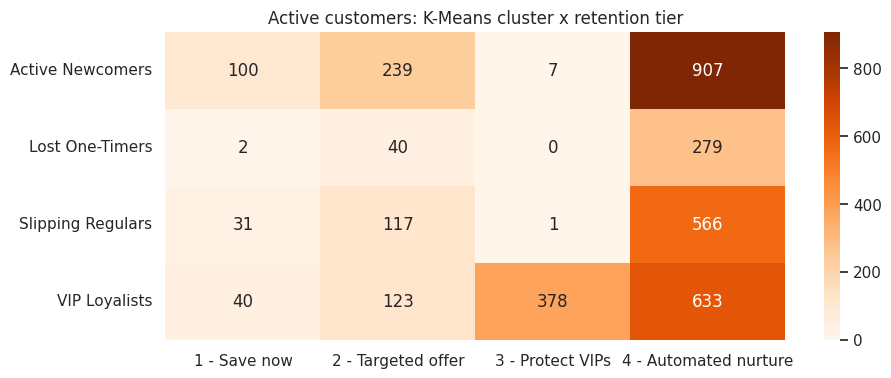

,size,mean
cluster_name,,
VIP Loyalists,1174,0.17
Slipping Regulars,715,0.51
Active Newcomers,1253,0.54
Lost One-Timers,321,0.71


In [8]:
# count of customers in each (K-Means cluster x tier) cell
ct = pd.crosstab(plan["cluster_name"], plan["tier"])
fig, ax = plt.subplots(figsize=(10, 4))
sns.heatmap(ct, annot=True, fmt="d", cmap="Oranges", ax=ax)
ax.set_title("Active customers: K-Means cluster x retention tier")
ax.set_xlabel(""); ax.set_ylabel("")
plt.savefig(IMAGES / "20_cluster_by_tier.png", dpi=150, bbox_inches="tight")
plt.show()

# average churn risk per cluster (is the model consistent with the segmentation?)
plan.groupby("cluster_name")["churn_risk"].agg(["size", "mean"]).sort_values("mean").round(3)

In [9]:
# which clusters do Tier 1 customers come from? (computed, not guessed)
(plan[plan["tier"] == "1 - Save now"]["cluster_name"].value_counts(normalize=True) * 100).round(0)

cluster_name
Active Newcomers    58.00
VIP Loyalists       23.00
Slipping Regulars   18.00
Lost One-Timers      1.00
Name: proportion, dtype: float64

**Evaluation (consistency check between the ML model and the clustering):** the two methods were built separately but agree: **VIP Loyalists have by far the lowest average churn risk (~0.17)** and the quieter clusters have much higher risk (0.5-0.7). That agreement increases my confidence that both capture real behaviour. The last table shows which clusters feed Tier 1; this tells the team *what kind* of customer they will be calling.

## Step 5 · The action list
**What:** map each tier (and cluster) to a recommended action and export a ranked list. **Why:** this CSV is the deliverable a marketing / account-management team could use on Monday morning.

In [10]:
# recommended action per tier (hypotheses to be A/B tested, I have no campaign response data)
actions = {
    "1 - Save now":          "Personal call/email from account manager: check last order, offer reorder of usual products + priority service",
    "2 - Targeted offer":    "Tailored email or call with a reorder reminder and a small time-limited incentive",
    "3 - Protect VIPs":      "Loyalty perks and early access to the autumn range; do NOT over-discount (they are healthy)",
    "4 - Automated nurture": "Standard automated flow: welcome / reorder reminders / seasonal newsletters",
}
plan["recommended_action"] = plan["tier"].map(actions)

action_list = (plan.sort_values("revenue_at_risk", ascending=False)
                   [["customer_id", "tier", "cluster_name", "segment", "churn_risk", "value_90d", "revenue_at_risk", "recommended_action"]]
                   .round({"churn_risk": 3, "value_90d": 0, "revenue_at_risk": 0}))
action_list.to_csv(OUTPUTS / "retention_action_list.csv", index=False)
tier_summary.round(2).to_csv(OUTPUTS / "retention_tier_summary.csv")

print("Top 15 customers to contact first (ranked by expected revenue at risk):")
action_list.head(15).drop(columns="recommended_action")

Top 15 customers to contact first (ranked by expected revenue at risk):


,customer_id,tier,cluster_name,segment,churn_risk,value_90d,revenue_at_risk
2141,16000,1 - Save now,VIP Loyalists,Potential Loyalists,0.25,"12,394.00","3,126.00"
5,12357,1 - Save now,Slipping Regulars,New / Recent Customers,0.55,"4,034.00","2,233.00"
1670,15195,1 - Save now,Active Newcomers,New / Recent Customers,0.57,"3,861.00","2,201.00"
270,12752,1 - Save now,Slipping Regulars,About To Sleep,0.46,"4,367.00","2,023.00"
227,12688,1 - Save now,Slipping Regulars,About To Sleep,0.47,"3,848.00","1,806.00"
127,12536,1 - Save now,Slipping Regulars,About To Sleep,0.39,"4,151.00","1,627.00"
2284,16240,1 - Save now,Active Newcomers,New / Recent Customers,0.34,"3,694.00","1,259.00"
643,13422,1 - Save now,Active Newcomers,About To Sleep,0.47,"2,602.00","1,234.00"
2902,17313,1 - Save now,Active Newcomers,New / Recent Customers,0.51,"2,288.00","1,156.00"
896,13868,1 - Save now,Active Newcomers,New / Recent Customers,0.36,"3,193.00","1,141.00"


## Step 6 · Customers who are already gone (not scored by the model)
Customers whose last order was **more than 180 days ago** were excluded from the churn model (it predicts *who is about to leave*, not who already left). They still matter: some were valuable and deserve a **one-off win-back attempt**.

In [11]:
lapsed = base[~base["customer_id"].isin(plan["customer_id"])].copy()            # customers in segments but not scored
lapsed = lapsed[lapsed["recency_days"] > 180]                                    # long silent

print(f"Lapsed customers (silent > 180 days): {len(lapsed):,} | their past net spend: £{lapsed['monetary'].sum():,.0f}")

# best win-back candidates = highest past spend AND repeat buyers (frequency >= 3), so they once had a real habit
winback = (lapsed[lapsed["frequency"] >= 3]
           .sort_values("monetary", ascending=False)
           [["customer_id", "cluster_name", "segment", "recency_days", "frequency", "monetary"]])
winback.to_csv(OUTPUTS / "winback_candidates.csv", index=False)
print(f"Win-back candidates (3+ past orders): {len(winback):,} customers, £{winback['monetary'].sum():,.0f} past net spend")
winback.head(10)

Lapsed customers (silent > 180 days): 2,369 | their past net spend: £2,119,498
Win-back candidates (3+ past orders): 737 customers, £1,441,915 past net spend


,customer_id,cluster_name,segment,recency_days,frequency,monetary
4325,16754,VIP Loyalists,Cant Lose Them,373,29,"54,692.82"
728,13093,VIP Loyalists,Cant Lose Them,276,55,"53,283.30"
5397,17850,VIP Loyalists,Cant Lose Them,373,155,"50,407.77"
2691,15098,Slipping Regulars,Needs Attention,183,3,"39,619.50"
1517,13902,Slipping Regulars,Cant Lose Them,633,5,"30,375.26"
132,12482,VIP Loyalists,Cant Lose Them,577,27,"21,941.72"
3338,15749,Slipping Regulars,At Risk,236,3,"21,535.90"
3394,15808,VIP Loyalists,Cant Lose Them,307,21,"17,038.95"
1184,13564,VIP Loyalists,Cant Lose Them,355,36,"15,613.10"
5006,17448,VIP Loyalists,Cant Lose Them,530,41,"14,375.01"


## Step 7 · What could a campaign be worth? (scenario, **not** a forecast)
I have **no data on campaign response**, so I cannot say what a campaign would achieve. What I *can* do is show how the result depends on an **assumption**: "if outreach prevents X% of the expected loss among Tier 1 customers...".

In [12]:
tier1_risk = plan.loc[plan["tier"] == "1 - Save now", "revenue_at_risk"].sum()          # expected loss in Tier 1
tier1_n = (plan["tier"] == "1 - Save now").sum()                                        # customers to contact

scenario = pd.DataFrame({"assumed_save_rate": [0.05, 0.10, 0.20]})                      # three optimistic/pessimistic cases
scenario["revenue_retained_90d"] = scenario["assumed_save_rate"] * tier1_risk           # money kept in each case
scenario["per_customer_contacted"] = scenario["revenue_retained_90d"] / tier1_n         # break-even thinking: how much can I spend per contact?
scenario["assumed_save_rate"] = (scenario["assumed_save_rate"] * 100).astype(int).astype(str) + "%"
print(f"Tier 1 = {tier1_n} customers, expected loss ~£{tier1_risk:,.0f} over 90 days")
scenario

Tier 1 = 173 customers, expected loss ~£101,657 over 90 days


,assumed_save_rate,revenue_retained_90d,per_customer_contacted
0,5%,"5,082.85",29.38
1,10%,"10,165.69",58.76
2,20%,"20,331.38",117.52


**How to read this:** the last column is the most I could spend per contacted customer and still break even under each assumption. Whether that is worth it depends on the cost of an account-manager call, which I do not know. The **real** next step would be an **A/B test**: contact half of Tier 1, leave the other half as a control group, compare re-order rates after 90 days.

**Caveats I want to be upfront about:** the churn probabilities are over-estimated (seasonal shift, notebook 03), the value proxy is simple, and customers can leave for reasons no purchase data can show.

## Final summary (what the whole project delivers)
| Part | What I built | Key takeaway |
|---|---|---|
| Notebook 01 | Cleaning + EDA of 1.07 M rows | 4 of the 5 biggest orders were cancelled → use *net* revenue; top 20% of customers ≈ 77% of revenue |
| SQL 01-05 | Schema, business KPIs, RFM, cohorts, churn features | Fixed an unfair `NTILE` scoring with `PERCENT_RANK`; ~81% of re-orders happen within 90 days |
| Notebook 02 | RFM vs K-Means (k = 4) | Log transform was essential; 4 stable clusters; VIP cluster ≈ 20% of customers, ≈ 74% of revenue |
| Notebook 03 | Churn model (time-based validation) | AUC ≈ 0.76 on active customers; frequency is the strongest driver; simple model ≈ tuned forest |
| Notebook 04 | Expected-loss tiers + action list | Value and risk are negatively related (ρ ≈ -0.8), so a risk × value grid failed (13 customers); ranking by expected loss gave Tier 1 = 173 customers (5%) holding ~19% of expected loss, Tiers 1+2 = 20% of customers, ~45% of loss |

**Files produced for the business:** `outputs/retention_action_list.csv`, `outputs/winback_candidates.csv`, `outputs/kmeans_cluster_profile.csv`.